# lanedet: step-by-step walk-through

This notebook runs each stage of the classical pipeline on one frame and shows its output:
original → colour/gradient masks → ROI → bird's-eye view → histogram → sliding windows and fit → overlay. It then runs a short clip to show temporal smoothing, and the Hough baseline.

By default it uses a **synthetic** frame (exact ground truth, no download). Set `IMAGE` to a path to try your own 1280x720 road image; you will probably need to re-tune the perspective points in `configs/default.yaml` first.

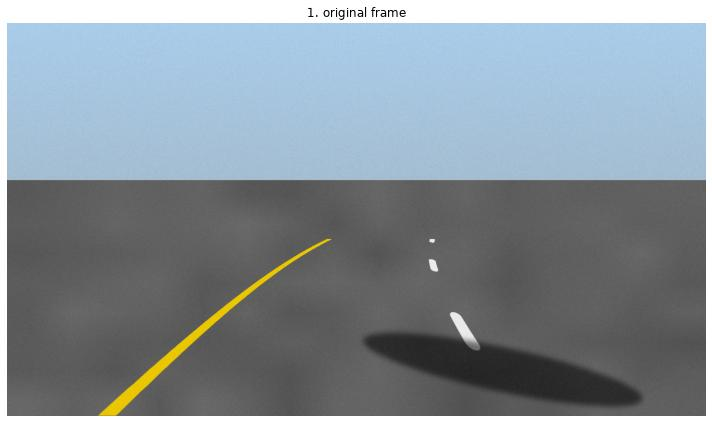

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from lanedet import LanePipeline, ThresholdMaskExtractor, load_config
from lanedet.hough import HoughLaneDetector
from lanedet.lanefit import SlidingWindowFinder, fit_lanes
from lanedet.overlay import draw_lanes, draw_search
from lanedet.synthetic import drive

%config InlineBackend.figure_format = 'jpeg'
plt.rcParams["figure.dpi"] = 72

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
config = load_config(ROOT / "configs" / "default.yaml")
IMAGE = None  # e.g. 'my_road.jpg'


def rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(images, titles, cols=2, size=6):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * 0.6 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, images, titles, strict=False):
        ax.imshow(rgb(img), cmap="gray")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


if IMAGE:
    frame = cv2.imread(IMAGE)
else:
    clip = [f for f, _ in drive(20, seed=4, scenario="shadow")]
    frame = clip[-1]
show([frame], ["1. original frame"], cols=1, size=10)

## 2. Binary lane mask
Yellow paint has high **saturation** in HLS; white paint has high **lightness**. Dark pixels are excluded from the saturation test because shadows give noisy, high S values. The **Sobel x-gradient** of lightness catches lane edges (lane lines are near-vertical in the image) even when the colour test misses faded paint. The two are OR-ed, closed, and clipped to the region of interest.

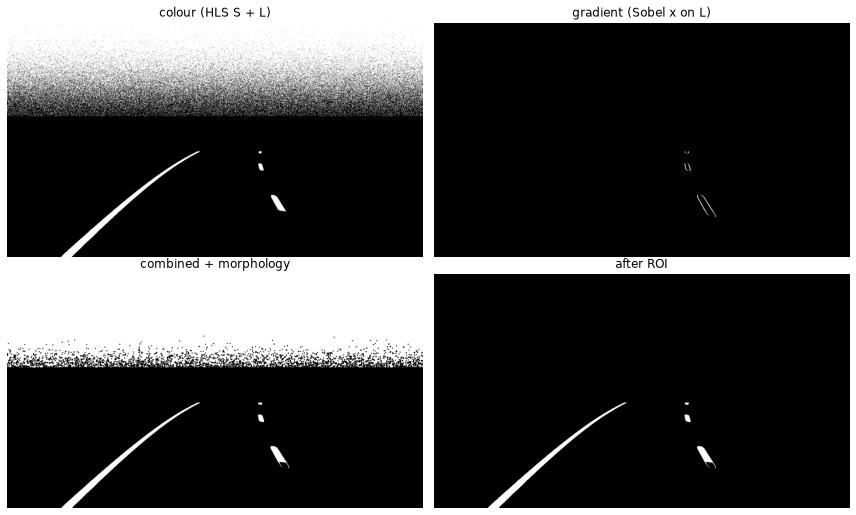

In [2]:
stages = ThresholdMaskExtractor(config.preprocess, config.roi).stages(frame)
show(
    [stages["color"], stages["gradient"], stages["combined"], stages["mask"]],
    ["colour (HLS S + L)", "gradient (Sobel x on L)", "combined + morphology", "after ROI"],
)

## 3. Bird's-eye view
Four points on the road (red trapezoid) are mapped to a rectangle, so parallel lane lines become parallel in the warped image and a polynomial `x = f(y)` describes each one.

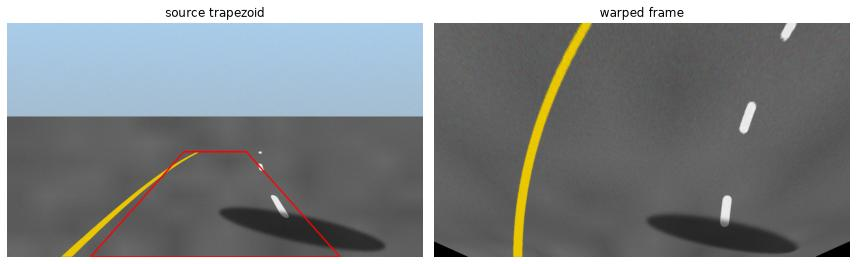

In [3]:
pipe = LanePipeline(config, use_tracker=False, debug=True)
result = pipe.process(frame)
T = pipe.transform
trap = frame.copy()
cv2.polylines(trap, [T.src.astype(np.int32)], True, (0, 0, 255), 3)
show([trap, T.warp(frame)], ["source trapezoid", "warped frame"])

## 4. Lane bases from a histogram
Summing the bottom half of the warped mask column by column gives two peaks: where the lane lines start next to the car.

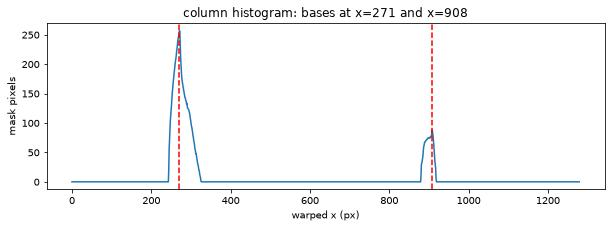

In [4]:
warped = result.debug["warped"]
hist = np.count_nonzero(warped[warped.shape[0] // 2 :], axis=0)
left_base, right_base = SlidingWindowFinder.find_bases(warped)
plt.figure(figsize=(10, 3))
plt.plot(hist)
for b in (left_base, right_base):
    plt.axvline(b, color="r", ls="--")
plt.title(f"column histogram: bases at x={left_base} and x={right_base}")
plt.xlabel("warped x (px)")
plt.ylabel("mask pixels")
plt.show()

## 5. Sliding windows and polynomial fit
Starting at each base, windows step up the image and re-centre on the pixels they contain. The collected pixels (red/blue) are fitted with a 2nd-order polynomial (yellow).

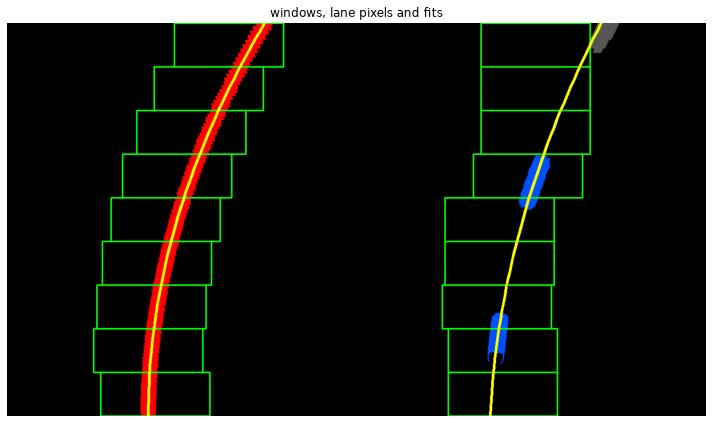

left  x = 4.159e-04*y^2 + -0.5955*y + 471.5
right x = 3.245e-04*y^2 + -0.5162*y + 1088.3


In [5]:
finder = SlidingWindowFinder.from_config(config.window)
pixels = finder.find(warped)
left, right = fit_lanes(pixels, config.window.min_fit_pixels)
show([draw_search(warped, pixels, left, right)], ["windows, lane pixels and fits"], cols=1, size=10)
for name, fit in (("left ", left), ("right", right)):
    a, b, c = fit.coeffs
    print(f"{name} x = {a:.3e}*y^2 + {b:.4f}*y + {c:.1f}")

## 6. Curvature and offset
Pixels become metres using the lane width (3.7 m spans the warped lane) and the road length the warped image covers (`view_length_m`). Radius: `R = (1 + (2Ay + B)^2)^1.5 / |2A|` at the row next to the car. Offset: camera centre minus lane centre (positive = car right of centre).

In [6]:
g = pipe.geometry
print(f"metres per pixel: x {g.xm:.5f}, y {g.ym:.5f}")
print(f"left radius  {g.curvature_radius(left):8.0f} m")
print(f"right radius {g.curvature_radius(right):8.0f} m")
print(f"combined     {result.curvature_m:8.0f} m")
print(f"offset       {result.offset_m:+8.2f} m")

metres per pixel: x 0.00578, y 0.04167
left radius       361 m
right radius      463 m
combined          406 m
offset          +0.40 m


## 7. Overlay
The lane polygon is mapped back into the camera view with the inverse transform.

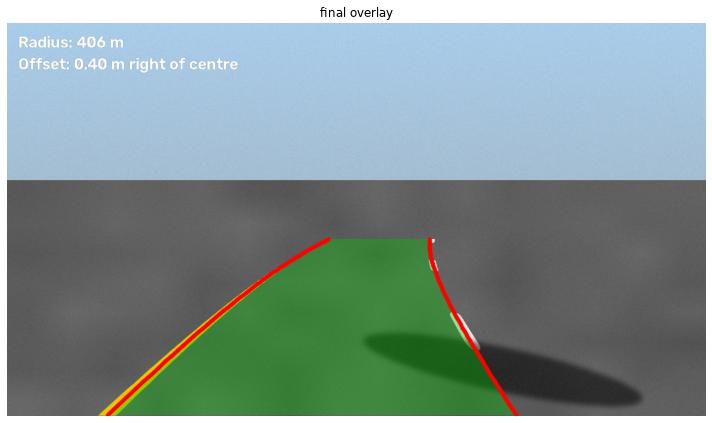

In [7]:
show([draw_lanes(frame, result, config.overlay)], ["final overlay"], cols=1, size=10)

## 8. Temporal smoothing on a clip
On a short drive, the tracker averages the last few accepted fits and rejects implausible ones. Here we blank out frames 40-42 to simulate a total detection failure: the raw pipeline loses the lane, the tracked one holds the last good estimate.

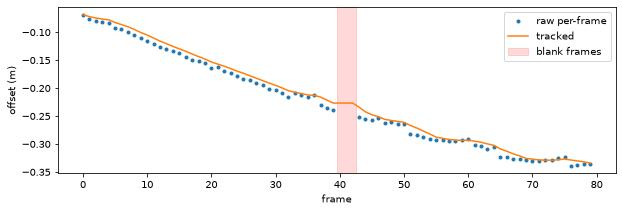

tracker rejected frames: [40, 41, 42]


In [8]:
frames = [f for f, _ in drive(80, seed=7, scenario="mixed")]
for i in (40, 41, 42):
    frames[i] = np.full_like(frames[i], 95)
raw, tracked = LanePipeline(config, use_tracker=False), LanePipeline(config, use_tracker=True)
r_off, t_off, accepted = [], [], []
for f in frames:
    a, b = raw.process(f), tracked.process(f)
    r_off.append(np.nan if a.offset_m is None else a.offset_m)
    t_off.append(np.nan if b.offset_m is None else b.offset_m)
    accepted.append(b.accepted)
plt.figure(figsize=(10, 3))
plt.plot(r_off, ".", label="raw per-frame")
plt.plot(t_off, "-", label="tracked")
plt.axvspan(39.5, 42.5, color="r", alpha=0.15, label="blank frames")
plt.ylabel("offset (m)")
plt.xlabel("frame")
plt.legend()
plt.show()
print("tracker rejected frames:", [i for i, ok in enumerate(accepted) if not ok])

## 9. Hough-line baseline
Canny edges + probabilistic Hough, one straight line per side. Cheap, but it cannot follow curves, which is why it loses accuracy on curved roads.

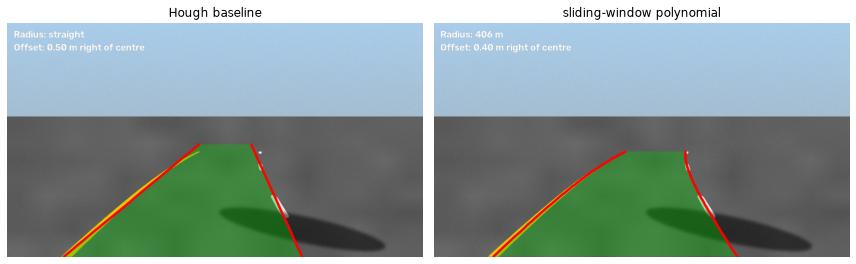

In [9]:
h = HoughLaneDetector(config).process(frame)
show(
    [draw_lanes(frame, h, config.overlay), draw_lanes(frame, result, config.overlay)],
    ["Hough baseline", "sliding-window polynomial"],
)